# Week 2 — Segment Comparison

Compare delivery KPIs across order status, purchase weekday, and product category.
This notebook uses the validated order-level KPI dataset and raw Olist files.
Results are descriptive, not causal.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data" / "interim" / "kpi_orders.csv").exists():
    ROOT = ROOT.parent

kpi_path = ROOT / "data" / "interim" / "kpi_orders.csv"
orders = pd.read_csv(kpi_path, parse_dates=[
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
])

print("Rows:", len(orders))
print("Unique orders:", orders["order_id"].nunique())
orders.head()

Rows: 99441
Unique orders: 99441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,approval_days,carrier_handoff_days,delivery_days,on_time_eligible,on_time,is_cancelled,small_sample
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,0.007431,2.366493,8.436574,True,True,False,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1.279745,0.462882,13.782037,True,True,False,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,0.011505,0.204595,9.394213,True,True,False,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,0.012419,3.745833,13.208750,True,True,False,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,0.042940,0.893113,2.873877,True,True,False,False


## 1. Order status distribution

,order_status,order_count,share_pct
3,delivered,96478,97.02
6,shipped,1107,1.11
1,canceled,625,0.63
7,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
2,created,5,0.01
0,approved,2,0.00


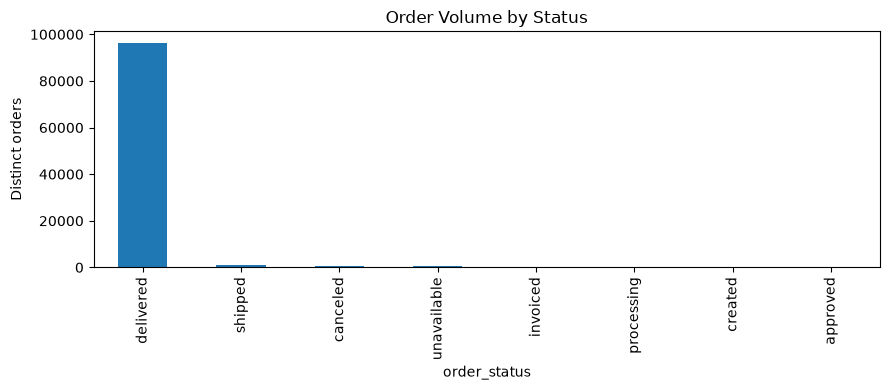

In [2]:
status_summary = (
    orders.groupby("order_status", dropna=False)
    .agg(order_count=("order_id", "nunique"))
    .reset_index()
    .sort_values("order_count", ascending=False)
)
status_summary["share_pct"] = (
    status_summary["order_count"] / orders["order_id"].nunique() * 100
).round(2)
display(status_summary)

status_summary.plot(
    x="order_status", y="order_count", kind="bar",
    legend=False, title="Order Volume by Status", figsize=(9, 4)
)
plt.ylabel("Distinct orders")
plt.tight_layout()
plt.show()

## 2. Delivery performance by purchase weekday

,purchase_weekday,delivered_orders,avg_delivery_days,median_delivery_days,on_time_rate_pct
1,Monday,15701,12.00,9.32,92.56
5,Tuesday,15503,12.08,9.30,92.95
6,Wednesday,15076,12.44,9.38,93.43
4,Thursday,14323,12.74,11.22,93.70
0,Friday,13685,13.57,11.36,92.98
2,Saturday,10555,13.36,10.95,93.41
3,Sunday,11635,11.96,9.78,93.78


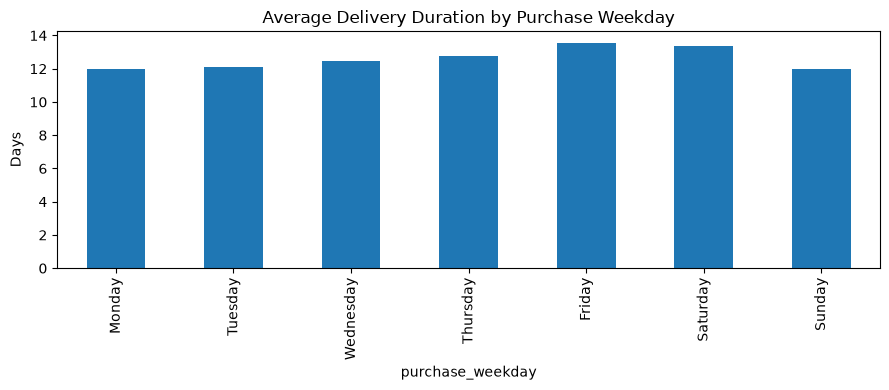

In [3]:
orders["purchase_weekday"] = (
    orders["order_purchase_timestamp"].dt.day_name()
)
orders["delivery_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

orders["on_time_eligible"] = (
    orders["order_status"].eq("delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
)
orders["on_time"] = (
    orders["on_time_eligible"]
    & (orders["order_delivered_customer_date"].dt.normalize()
       <= orders["order_estimated_delivery_date"].dt.normalize())
)

delivered = orders[orders["order_status"].eq("delivered")].copy()
weekday_summary = (
    delivered.groupby("purchase_weekday", dropna=False)
    .agg(
        delivered_orders=("order_id", "nunique"),
        avg_delivery_days=("delivery_days", "mean"),
        median_delivery_days=("delivery_days", "median"),
    )
    .reset_index()
)
eligible = orders[orders["on_time_eligible"]].groupby(
    "purchase_weekday"
)["on_time"].mean().mul(100).rename("on_time_rate_pct")
weekday_summary = weekday_summary.merge(
    eligible, on="purchase_weekday", how="left"
)
weekday_summary[["avg_delivery_days", "median_delivery_days",
                 "on_time_rate_pct"]] = weekday_summary[
    ["avg_delivery_days", "median_delivery_days", "on_time_rate_pct"]
].round(2)

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
weekday_summary["purchase_weekday"] = pd.Categorical(
    weekday_summary["purchase_weekday"],
    categories=weekday_order, ordered=True
)
weekday_summary = weekday_summary.sort_values("purchase_weekday")
display(weekday_summary)

weekday_summary.plot(
    x="purchase_weekday", y="avg_delivery_days", kind="bar",
    legend=False, title="Average Delivery Duration by Purchase Weekday",
    figsize=(9, 4)
)
plt.ylabel("Days")
plt.tight_layout()
plt.show()

## 3. Product category comparison

,category,order_count,small_sample,cancelled_orders,cancellation_rate_pct,delivered_order_count,avg_delivery_days,on_time_eligible_orders,on_time_rate_pct
0,bed_bath_table,9417,False,18,0.19,9272,12.99,9272,92.57
1,health_beauty,8836,False,36,0.41,8647,12.08,8647,92.49
2,sports_leisure,7720,False,47,0.61,7529,12.24,7529,93.43
3,computers_accessories,6689,False,35,0.52,6529,13.17,6529,93.61
4,furniture_decor,6449,False,24,0.37,6307,13.07,6307,92.88
5,housewares,5884,False,37,0.63,5743,11.09,5743,94.64
6,watches_gifts,5624,False,20,0.36,5493,12.81,5493,92.61
7,telephony,4199,False,16,0.38,4093,12.96,4093,92.89
8,auto,3897,False,24,0.62,3809,12.33,3809,92.70
9,toys,3886,False,31,0.80,3803,11.73,3803,93.61


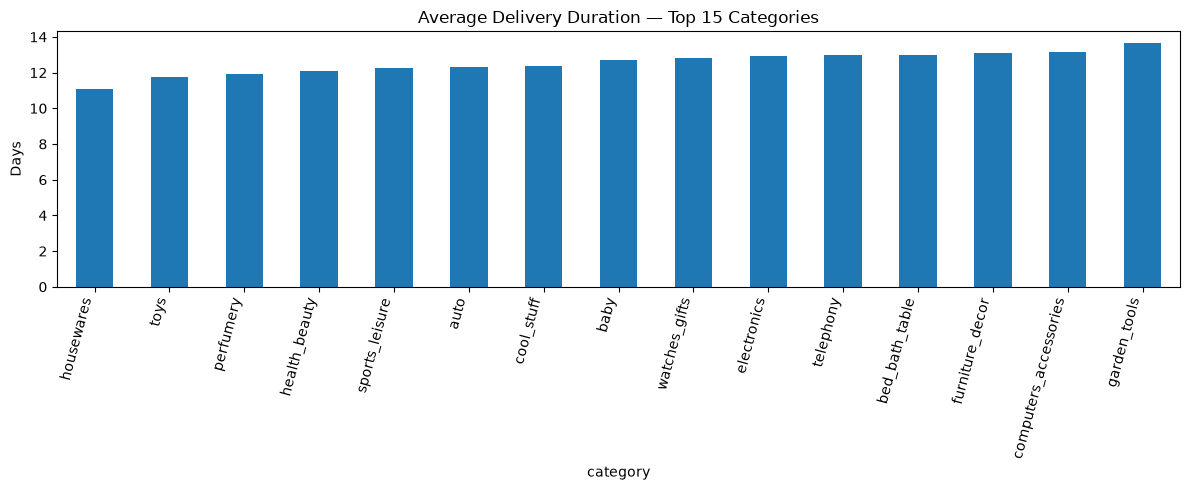

In [4]:
category_path = ROOT / "reports" / "tables" / "kpi_by_category.csv"
category = pd.read_csv(category_path)
display(category.head(15))

category.sort_values("avg_delivery_days").plot(
    x="category", y="avg_delivery_days", kind="bar",
    legend=False, title="Average Delivery Duration — Top 15 Categories",
    figsize=(12, 5)
)
plt.ylabel("Days")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## 4. Interpretation and limitations

- Order status counts describe order outcomes; they do not explain why an order was canceled.
- Weekday comparisons are descriptive and may be affected by product mix, geography, seasonality, and carrier operations.
- Delivery duration includes only delivered orders with valid timestamps.
- On-time rate uses delivered orders with both actual and estimated delivery dates.
- Category order counts can overlap when an order contains products from multiple categories.
- Validate KPI definitions and figures against the team's SQL results before final submission.